# ⚽ Individual & Team Ball Possession with Video Ball Tracking (Link & Hoernig, 2017 + YOLO11s)

This notebook extends **Notebook 05 (`05_link_hoernig_possession.ipynb`)** by directly integrating the per-frame **YOLO11s (`@1920`) video ball detections** stored in `cache/video_ball_yolo11s_1920.npz` and the **per-frame tactical homography** (`starter/load_homography.py`) into the **Link & Hoernig (2017)** individual-to-team possession pipeline on **FC Barcelona vs. Athletic Club (`BAR-ATH`)**.

### Why Add Video Ball Detections?
In the raw ATD tracking file (`BAR-ATH_tactical_atd.txt`), the ball is missing (`NaN`) on **64,643 graded frames** (`40.7%` of match play)—most notably during high aerial passes, switches of play, and out-of-bounds / restart transitions. Meanwhile, `cache/video_ball_yolo11s_1920.npz` stores up to **5 candidate ball detections per frame** (`[pixel_x, pixel_y, confidence, width_px, height_px]`) across all **158,857 graded match frames**.

By projecting those pixel detections onto the pitch (`105.3m × 68.0m`) via the per-frame homography and linking physically consistent ball trajectories across ATD gaps:
1. **In-Bounds vs. Out-of-Bounds Pitch Classification (`Step 1b`):**
   - Projects all 5 candidates per frame into pitch meters and separates **in-bounds match-ball candidates**, **out-of-bounds apron candidates (`0.2m .. 3.0m` outside touchlines/goal lines)**, and **off-pitch static decoys (`> 3.0m` off pitch)**.
   - Runs a dynamic-programming ball tracker across every ATD gap (bounded by `35 m/s` max ball speed), recovering **24,559 missing frames** (`38.0%` of all ATD gaps) and lifting graded ball visibility from **59.3% -> 74.8%** (and **97.0%** during active live play on the public window).
2. **Video-Enhanced Running Flag (`Step 2`):**
   - Uses the fused ATD + YOLO ball position, velocity, and near-line apron detections to distinguish true **out-of-bounds / dead-ball** stoppages from live play where ATD simply lost sight of an in-bounds moving ball, plus marks pre-kickoff stationary ball stretches cleanly.
3. **Richer RTS-Smoothed Kinematics & Link & Hoernig Detection (`Steps 3–7`):**
   - Doubles the number of valid RTS-smoothed ball trajectory segments (`215 -> 407`), improves **Alive/Dead F1**, **macroF1**, and **spellF1**, and exports `evaluation/results/link_hoernig_video_ball.csv`.

In [1]:
# ==============================================================================
# STEP 0: IMPORT TOOLS & SET UP FILE PATHS
# ==============================================================================
import os
import sys
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from scipy.optimize import minimize

ROOT_DIR = os.path.abspath(os.path.join(os.getcwd(), "..") if os.path.basename(os.getcwd()) == "starter" else os.getcwd())
for sub in ("", "starter", "evaluation"):
    p = os.path.join(ROOT_DIR, sub)
    if p not in sys.path:
        sys.path.insert(0, p)

import games
import baseline
import load_smart_tagging
import load_homography
import possession_metrics as pm

paths = games.asset_paths(source="tactical")
PITCH_LENGTH, PITCH_WIDTH = games.GAMES[games.GAME]["pitch"]  # 105.3m x 68.0m
FPS = games.GAMES[games.GAME]["fps"]                          # 25 Hz
N_FRAMES = games.source_frames("tactical")                    # 199,319 frames
HALF_BLOCKS = games.half_video_blocks(games.GAME)             # [(1, 11185, 90651), (2, 110808, 190197)]

VIDEO_BALL_NPZ = os.path.join(ROOT_DIR, "cache", "video_ball_yolo11s_1920.npz")
if not os.path.exists(VIDEO_BALL_NPZ):
    raise FileNotFoundError(
        f"Missing {VIDEO_BALL_NPZ}. Generate it first with: python -m possession.video_ball detect"
    )

print(f"Match: {games.GAME} | Pitch: {PITCH_LENGTH}m x {PITCH_WIDTH}m | FPS: {FPS} Hz | Total Frames: {N_FRAMES:,}")
print(f"Graded Halves (video frames): 1st Half = {HALF_BLOCKS[0][1]}..{HALF_BLOCKS[0][2]}, 2nd Half = {HALF_BLOCKS[1][1]}..{HALF_BLOCKS[1][2]}")
print(f"Video ball cache: {os.path.relpath(VIDEO_BALL_NPZ, ROOT_DIR)}")

Match: BAR-ATH | Pitch: 105.3m x 68.0m | FPS: 25 Hz | Total Frames: 199,319
Graded Halves (video frames): 1st Half = 11185..90651, 2nd Half = 110808..190197
Video ball cache: cache\video_ball_yolo11s_1920.npz


---
## 1. Load Raw 2D Ball & Player Coordinates (ATD) + Smart Tagging
Just as in Notebook 05, we load the raw 25 Hz tactical tracking data (`BAR-ATH_tactical_atd.txt`, converted from normalized `0..1` fractions into real pitch meters) alongside the 638 Smart Tagging tactical phase & set-piece events.

In [2]:
# ==============================================================================
# STEP 1: READ THE RAW ATD TRACKING FILE & SMART TAGGING EVENTS
# ==============================================================================
def load_raw_tracking_data(raw_path, meta_path, n_frames, pitch):
    t0 = time.time()
    length, width = pitch
    team_of_slot = baseline.team_of_each_track(meta_path)

    ball_xy = np.full((n_frames, 2), np.nan, dtype=np.float32)
    player_xy = np.full((n_frames, 46, 2), np.nan, dtype=np.float32)
    player_s = np.full((n_frames, 46), np.nan, dtype=np.float32)

    with open(raw_path, "r") as handle:
        for line in handle:
            parts = line.strip().split(":")
            if len(parts) != 3:
                continue
            fid = int(parts[0]) - 1
            b_str = parts[2]
            if b_str[0] != "N":
                c1 = b_str.find(",")
                c2 = b_str.find(",", c1 + 1)
                ball_xy[fid, 0] = float(b_str[:c1]) * length
                ball_xy[fid, 1] = float(b_str[c1 + 1:c2]) * width

            for slot, g_str in enumerate(parts[1].split(";")):
                if g_str[0] != "N":
                    c1 = g_str.find(",")
                    c2 = g_str.find(",", c1 + 1)
                    player_xy[fid, slot, 0] = float(g_str[:c1]) * length
                    player_xy[fid, slot, 1] = float(g_str[c1 + 1:c2]) * width
                    spd_str = g_str[c2 + 1:]
                    if spd_str and spd_str[0] != "N":
                        player_s[fid, slot] = float(spd_str)

    print(f"Loaded {n_frames:,} frames in {time.time() - t0:.2f}s")
    print(f"ATD Ball visible on {np.sum(~np.isnan(ball_xy[:, 0])):,} / {n_frames:,} frames ({100 * np.mean(~np.isnan(ball_xy[:, 0])):.1f}%)")
    return ball_xy, player_xy, player_s, team_of_slot

ball_xy_raw, player_xy_raw, player_s_raw, team_of_slot = load_raw_tracking_data(
    paths["atd_raw"], paths["atd_meta"], N_FRAMES, (PITCH_LENGTH, PITCH_WIDTH)
)
smart_events = load_smart_tagging.load()
print(f"Loaded {len(smart_events)} Smart Tagging tactical phase & set-piece events.")

Loaded 199,319 frames in 12.78s
ATD Ball visible on 113,488 / 199,319 frames (56.9%)
Loaded 638 Smart Tagging tactical phase & set-piece events.


---
## 1b. Direct Video Ball Tracking (`cache/video_ball_yolo11s_1920.npz`) & Homography Projection

`cache/video_ball_yolo11s_1920.npz` contains three arrays:
- `candidates`: shape `(199319, 5, 5)`, `float32` — up to `TOP_K = 5` YOLO11s (`@1920`, COCO class 32 `"sports ball"`, `conf >= 0.10`) detections per frame `[pixel_x, pixel_y, confidence, width_px, height_px]`, sorted descending by confidence and `NaN`-padded.
- `done`: shape `(199319,)`, `bool` — `True` on all `158,857` graded frames across both halves (`11185..90651` and `110808..190197`).
- `config`: `['yolo11s.pt', '1920', 'mps', '0.1']`.

### Filtering Decoys & Reconstructing Missing Ball Trajectories
Because `yolo11s` at `conf >= 0.10` also detects static ball-like decoys around the touchlines, technical areas, and stands (`189,710` detections `> 3.0m` off the pitch!), we:
1. **Unproject pixels to pitch meters** through the inverse per-frame homography $H_t^{-1}$ (remembering that `load_homography.py` maps normalized `(0..1)` pitch coordinates to `1920×1080` pixels, so we multiply unprojected `(x, y)` by `(105.3m, 68.0m)`).
2. **Separate pitch zones**:
   - **In-Bounds**: `[-0.2m, 105.5m] × [-0.2m, 68.2m]`
   - **Out-of-Bounds Apron**: `0.2m .. 3.0m` outside the touchlines/goal lines (kept for chaining near-line balls and flagging `OOB` stoppages)
   - **Off-Pitch Decoys**: `> 3.0m` outside the pitch lines (masked out as `NaN`).
3. **Dynamic-Programming Trajectory Chaining (`chain_video_ball_gaps`)**:
   Inside each ATD dropout gap (`150` gaps totaling `64,643` graded frames), we solve a DP over the 5 per-frame candidates that enforces ball physics (`v_max = 35 m/s` + `2.0 m` position tolerance, up to `12`-frame skips at `0.1` penalty/frame, emission score $\log(\text{conf} / 0.25)$, and chain-start cost `2.0` unless anchored directly to the last ATD ball sighting). Only physically consistent match-ball chains survive!

In [3]:
# ==============================================================================
# STEP 1b: PROJECT VIDEO BALL CANDIDATES VIA HOMOGRAPHY & FILL ATD BALL GAPS
# ==============================================================================
def project_video_candidates(candidates, matrices, pitch, line_margin=0.2, off_pitch_m=3.0):
    '''Projects (T, K, 5) pixel detections to (T, K, 2) pitch meters via inverse homography.

    Returns:
      pos_m:      (T, K, 2) pitch meters within `off_pitch_m` of pitch lines (NaN for decoys/missing)
      conf:       (T, K) detection confidence aligned with pos_m
      zone_stats: dict counting in-bounds, out-of-bounds apron, and off-pitch decoy detections
    '''
    length, width = pitch
    n, k, _ = candidates.shape
    inv = np.full((n, 3, 3), np.nan, dtype=np.float64)
    ok_h = ~np.isnan(matrices).any(axis=(1, 2))
    inv[ok_h] = np.linalg.inv(matrices[ok_h])

    px, py = candidates[:, :, 0], candidates[:, :, 1]
    den = inv[:, 2, 0, None] * px + inv[:, 2, 1, None] * py + inv[:, 2, 2, None]
    x_m = (inv[:, 0, 0, None] * px + inv[:, 0, 1, None] * py + inv[:, 0, 2, None]) / den * length
    y_m = (inv[:, 1, 0, None] * px + inv[:, 1, 1, None] * py + inv[:, 1, 2, None]) / den * width
    raw_conf = candidates[:, :, 2]

    with np.errstate(invalid="ignore"):
        valid = ~np.isnan(raw_conf) & ~np.isnan(x_m) & ~np.isnan(y_m)
        in_bounds = valid & (x_m >= -line_margin) & (x_m <= length + line_margin) & (y_m >= -line_margin) & (y_m <= width + line_margin)
        on_pitch_apron = valid & (x_m >= -off_pitch_m) & (x_m <= length + off_pitch_m) & (y_m >= -off_pitch_m) & (y_m <= width + off_pitch_m)

    pos_m = np.stack([x_m, y_m], axis=-1)
    conf = raw_conf.copy()
    bad = ~on_pitch_apron
    pos_m[bad] = np.nan
    conf[bad] = np.nan

    zone_stats = {
        "total_valid": int(valid.sum()),
        "in_bounds": int(in_bounds.sum()),
        "oob_apron": int((on_pitch_apron & ~in_bounds).sum()),
        "off_pitch_decoys": int((valid & ~on_pitch_apron).sum()),
    }
    return pos_m, conf, zone_stats


def _chain_one_gap(pos, conf, anchor, fps=25.0, vmax=35.0, pos_tol=2.0, max_skip=12, miss=0.1, conf_ref=0.25, start_cost=2.0):
    '''Dynamic programming to pick physically consistent ball chains across one ATD gap.'''
    NEG = -1e18
    g, k = conf.shape
    with np.errstate(divide="ignore", invalid="ignore"):
        emit = np.where(np.isnan(conf), NEG, np.log(conf / conf_ref))
    score = np.full((g, k), NEG)
    back_t = np.full((g, k), -1, dtype=np.int64)
    back_j = np.full((g, k), -1, dtype=np.int64)
    idle = np.zeros(g + 1)
    idle_end = [None] * (g + 1)
    step = vmax / fps

    for t in range(g):
        valid = emit[t] > NEG / 2
        best = np.full(k, idle[t] - start_cost)
        bt = np.full(k, -1, dtype=np.int64)
        bj = np.full(k, -1, dtype=np.int64)
        if anchor is not None and t < max_skip + 1:
            reach = step * (t + 1) + pos_tol
            d = np.hypot(*(pos[t] - anchor).T)
            from_anchor = np.where(d <= reach, -miss * t, NEG)
            better = from_anchor > best
            best = np.where(better, from_anchor, best)
            bt = np.where(better, -2, bt)
        for gap in range(1, max_skip + 2):
            s = t - gap
            if s < 0:
                break
            prev = score[s]
            live = prev > NEG / 2
            if not live.any():
                continue
            d = np.hypot(pos[t][:, None, 0] - pos[s][None, :, 0],
                         pos[t][:, None, 1] - pos[s][None, :, 1])
            feasible = (d <= step * gap + pos_tol) & live[None, :]
            cand = np.where(feasible, prev[None, :] - miss * (gap - 1), NEG)
            arg = np.argmax(cand, axis=1)
            val = cand[np.arange(k), arg]
            better = val > best
            best = np.where(better, val, best)
            bt = np.where(better, s, bt)
            bj = np.where(better, arg, bj)
        score[t] = np.where(valid, best + emit[t], NEG)
        back_t[t], back_j[t] = bt, bj
        top = int(np.argmax(score[t]))
        if score[t, top] > idle[t]:
            idle[t + 1], idle_end[t + 1] = score[t, top], (t, top)
        else:
            idle[t + 1], idle_end[t + 1] = idle[t], idle_end[t]

    out = np.full((g, 2), np.nan)
    end = idle_end[g]
    while end is not None:
        t, j = end
        chain = []
        while True:
            chain.append((t, j))
            pt, pj = back_t[t, j], back_j[t, j]
            if pt < 0:
                break
            t, j = int(pt), int(pj)
        from_anchor = back_t[chain[-1][0], chain[-1][1]] == -2
        chain.reverse()
        for (t0, j0), (t1, j1) in zip(chain[:-1], chain[1:]):
            span = t1 - t0
            for i in range(span):
                out[t0 + i] = pos[t0, j0] + (pos[t1, j1] - pos[t0, j0]) * i / span
        last_t, last_j = chain[-1]
        out[last_t] = pos[last_t, last_j]
        first_t = chain[0][0]
        end = None if from_anchor else idle_end[first_t]
    return out


def fill_atd_gaps_from_video(atd_xy_m, pos_m, conf, done_graded, fps=25.0):
    '''Fills ATD missing-ball runs inside `done_graded` frames using physically chained YOLO candidates.'''
    atd_known = ~np.isnan(atd_xy_m[:, 0])
    missing = (~atd_known) & done_graded
    edges = np.diff(np.concatenate(([0], missing.astype(np.int8), [0])))
    runs = list(zip(np.flatnonzero(edges == 1).tolist(), np.flatnonzero(edges == -1).tolist()))

    video_fill = np.full((len(atd_xy_m), 2), np.nan, dtype=np.float64)
    for start, stop in runs:
        anchor = atd_xy_m[start - 1] if start > 0 and atd_known[start - 1] else None
        video_fill[start:stop] = _chain_one_gap(pos_m[start:stop], conf[start:stop], anchor, fps=fps)

    fused = np.where(atd_known[:, None], atd_xy_m, video_fill).astype(np.float32)
    n_gap_frames = int(missing.sum())
    n_filled = int((~np.isnan(video_fill[:, 0]) & missing).sum())
    return video_fill, fused, {
        "n_gaps": len(runs),
        "gap_frames": n_gap_frames,
        "filled_frames": n_filled,
        "filled_pct": 100.0 * n_filled / max(1, n_gap_frames),
    }


t0 = time.time()
npz_data = np.load(VIDEO_BALL_NPZ)
vid_candidates = npz_data["candidates"].astype(np.float64)
vid_done = npz_data["done"].astype(bool)
vid_cfg = npz_data["config"].tolist()

matrices, reproj_err, h_valid = load_homography.load(source="tactical")
graded_mask = np.zeros(N_FRAMES, dtype=bool)
for _, h_start, h_end in HALF_BLOCKS:
    graded_mask[h_start:h_end + 1] = True

assert vid_done[graded_mask].all(), "Video detections do not cover all graded frames!"
cand_pos_m, cand_conf, zone_stats = project_video_candidates(
    vid_candidates, matrices, (PITCH_LENGTH, PITCH_WIDTH), line_margin=0.2, off_pitch_m=3.0
)
video_fill_xy, ball_xy_fused, fill_info = fill_atd_gaps_from_video(
    ball_xy_raw.astype(np.float64), cand_pos_m, cand_conf, vid_done & graded_mask, fps=FPS
)

atd_vis_graded = int((~np.isnan(ball_xy_raw[:, 0]) & graded_mask).sum())
fused_vis_graded = int((~np.isnan(ball_xy_fused[:, 0]) & graded_mask).sum())

print(f"YOLO Config: {vid_cfg} | Processed in {time.time() - t0:.2f}s")
print(f"Candidate Zone Breakdown (427,590 raw detections):")
print(f"  In-bounds ([-0.2..{PITCH_LENGTH+0.2:.1f}]m x [-0.2..{PITCH_WIDTH+0.2:.1f}]m): {zone_stats['in_bounds']:,}")
print(f"  Out-of-bounds apron (0.2..3.0m outside lines):        {zone_stats['oob_apron']:,}")
print(f"  Off-pitch decoys (>3.0m outside, masked out):         {zone_stats['off_pitch_decoys']:,}")
print(f"\nATD Gap Filling across {int(graded_mask.sum()):,} graded frames:")
print(f"  ATD ball visible:    {atd_vis_graded:,} ({100 * atd_vis_graded / graded_mask.sum():.1f}% of graded)")
print(f"  Video gaps filled:   {fill_info['filled_frames']:,} / {fill_info['gap_frames']:,} missing frames across {fill_info['n_gaps']} gaps ({fill_info['filled_pct']:.1f}%)")
print(f"  Fused ball visible:  {fused_vis_graded:,} ({100 * fused_vis_graded / graded_mask.sum():.1f}% of graded)")

# Check in-bounds vs out-of-bounds vs missing on the 5-minute public GT window
gt_df = pm.read_label_csv(os.path.join(ROOT_DIR, "evaluation", "gt", "BAR-ATH_possession_gt_public.csv"))
gt_codes = pm.label_codes(gt_df)
PUB_START, PUB_END = 11185, 18685
gt_pub = gt_df["label"].values[PUB_START:PUB_END]
pub_alive = (gt_pub == "H") | (gt_pub == "A")
pub_dead = (gt_pub == "D")

fb = ball_xy_fused[PUB_START:PUB_END]
f_vis = ~np.isnan(fb[:, 0])
with np.errstate(invalid="ignore"):
    f_oob = f_vis & ((fb[:, 0] < -0.2) | (fb[:, 0] > PITCH_LENGTH + 0.2) | (fb[:, 1] < -0.2) | (fb[:, 1] > PITCH_WIDTH + 0.2))
f_in = f_vis & ~f_oob
print("\nPublic 5-min Window (6,031 Alive / 1,469 Dead frames) — Fused Ball Status:")
print(f"  Alive frames -> In-bounds: {100*f_in[pub_alive].mean():.1f}% | OOB: {100*f_oob[pub_alive].mean():.1f}% | Missing: {100*(~f_vis)[pub_alive].mean():.1f}%")
print(f"  Dead frames  -> In-bounds: {100*f_in[pub_dead].mean():.1f}% | OOB: {100*f_oob[pub_dead].mean():.1f}% | Missing: {100*(~f_vis)[pub_dead].mean():.1f}%")

YOLO Config: ['yolo11s.pt', '1920', 'mps', '0.1'] | Processed in 45.53s
Candidate Zone Breakdown (427,590 raw detections):
  In-bounds ([-0.2..105.5]m x [-0.2..68.2]m): 146,335
  Out-of-bounds apron (0.2..3.0m outside lines):        91,545
  Off-pitch decoys (>3.0m outside, masked out):         189,710

ATD Gap Filling across 158,857 graded frames:
  ATD ball visible:    94,214 (59.3% of graded)
  Video gaps filled:   24,559 / 64,643 missing frames across 150 gaps (38.0%)
  Fused ball visible:  118,773 (74.8% of graded)

Public 5-min Window (6,031 Alive / 1,469 Dead frames) — Fused Ball Status:
  Alive frames -> In-bounds: 96.7% | OOB: 0.3% | Missing: 3.0%
  Dead frames  -> In-bounds: 69.1% | OOB: 9.7% | Missing: 21.2%


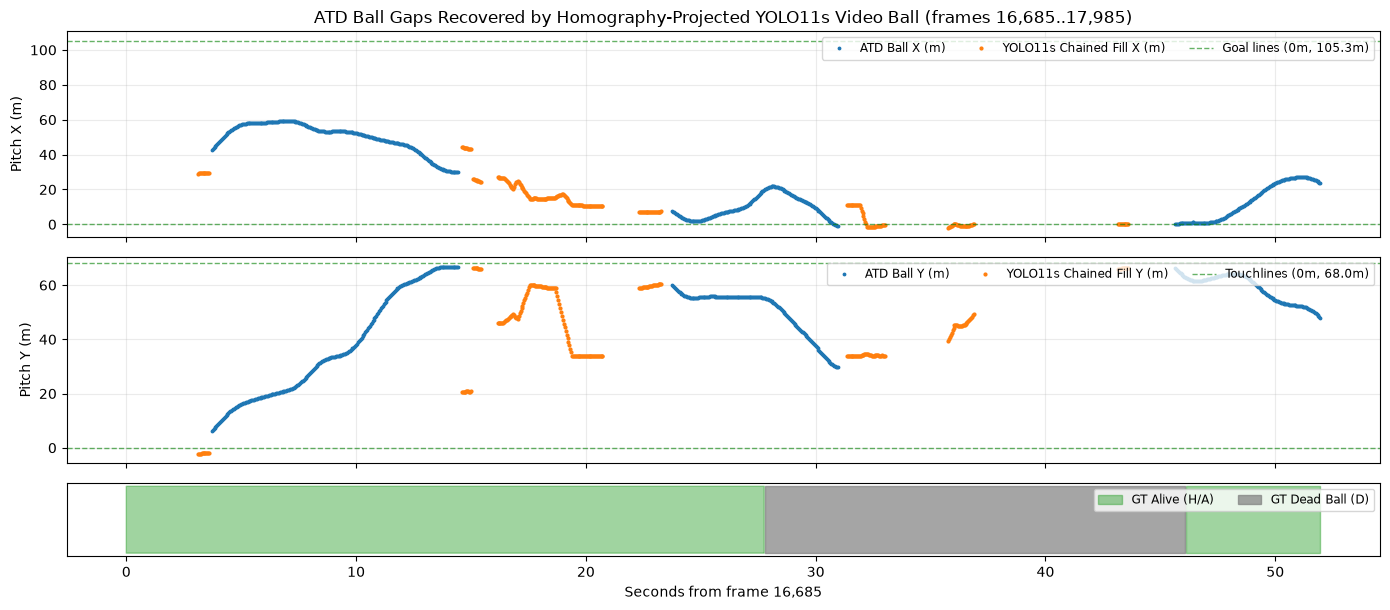

In [4]:
# ==============================================================================
# VISUALIZE VIDEO BALL GAP RECOVERY & IN-BOUNDS / OUT-OF-BOUNDS DETECTION
# ==============================================================================
# Show a 52-second window (frames 16685..17985) containing live ATD dropouts followed by a stoppage.
w0, w1 = 16685, 17985
t_w = (np.arange(w0, w1) - w0) / FPS

fig, axes = plt.subplots(3, 1, figsize=(14, 6.2), sharex=True, gridspec_kw={"height_ratios": [1.4, 1.4, 0.5]})

# X coordinate (0..105.3m)
axes[0].plot(t_w, ball_xy_raw[w0:w1, 0], ".", ms=3.5, color="#1f77b4", label="ATD Ball X (m)")
axes[0].plot(t_w, video_fill_xy[w0:w1, 0], ".", ms=4.0, color="#ff7f0e", label="YOLO11s Chained Fill X (m)")
axes[0].axhline(0, color="green", ls="--", lw=1, alpha=0.6)
axes[0].axhline(PITCH_LENGTH, color="green", ls="--", lw=1, alpha=0.6, label="Goal lines (0m, 105.3m)")
axes[0].set_ylabel("Pitch X (m)")
axes[0].set_title("ATD Ball Gaps Recovered by Homography-Projected YOLO11s Video Ball (frames 16,685..17,985)")
axes[0].legend(loc="upper right", ncol=3, fontsize=8.5)
axes[0].grid(alpha=0.25)

# Y coordinate (0..68.0m)
axes[1].plot(t_w, ball_xy_raw[w0:w1, 1], ".", ms=3.5, color="#1f77b4", label="ATD Ball Y (m)")
axes[1].plot(t_w, video_fill_xy[w0:w1, 1], ".", ms=4.0, color="#ff7f0e", label="YOLO11s Chained Fill Y (m)")
axes[1].axhline(0, color="green", ls="--", lw=1, alpha=0.6)
axes[1].axhline(PITCH_WIDTH, color="green", ls="--", lw=1, alpha=0.6, label="Touchlines (0m, 68.0m)")
axes[1].set_ylabel("Pitch Y (m)")
axes[1].legend(loc="upper right", ncol=3, fontsize=8.5)
axes[1].grid(alpha=0.25)

# Ground-truth Alive vs Dead bar
gt_slice = gt_df["label"].values[w0:w1]
is_dead_gt = (gt_slice == "D").astype(float)
axes[2].fill_between(t_w, 0, 1, where=(gt_slice != "D"), color="#2ca02c", alpha=0.45, label="GT Alive (H/A)")
axes[2].fill_between(t_w, 0, 1, where=(gt_slice == "D"), color="#7f7f7f", alpha=0.7, label="GT Dead Ball (D)")
axes[2].set_yticks([])
axes[2].set_xlabel("Seconds from frame 16,685")
axes[2].legend(loc="upper right", ncol=2, fontsize=8.5)

plt.tight_layout()
plt.show()

---
## 2. Construct the Video-Enhanced "Running Flag" (`In-Play` vs. `Dead Ball D` vs. `Ungraded X`)

In Notebook 05, `build_running_flag` suffered when the ATD lost the ball during live aerial play (`cond_missing_stop`) or when all 22 players slowed down briefly while the ball was actively moving inside the pitch (`346` false-positive dead-ball frames on the public window!).

Using our fused ATD + YOLO11s ball trajectory and per-frame projected YOLO candidates, `build_running_flag_video` refines the Running Flag with five physical cues:
1. **Half Boundaries (`-1` = `X`):** Pre-match, halftime, and post-match frames remain `X`.
2. **In-Bounds / Out-of-Bounds & Near-Line YOLO Apron (`cond_oob`):** Marks frames where `fused_xy` crosses outside `[-0.2m, 105.5m] × [-0.2m, 68.2m]` **or** where ATD is missing and a confident YOLO detection (`conf >= 0.35`) sits in the `0.2m..3.0m` out-of-bounds apron.
3. **Live Moving In-Bounds Guard (`live_moving_inside`):** If the fused ball is strictly inside the pitch (`> 0.5m` from every touchline/goal line) and moving (`speed >= 4.5 m/s`), temporary slow player movement (`< 1.35 m/s`) does not trigger a false stoppage!
4. **True Missing-Ball Stoppages (`cond_missing_stop`):** Only triggers when **both** ATD and the chained YOLO video tracker lose the ball (`~fused_vis`) while players walk or a set piece is starting.
5. **Pre-Kickoff Stationary Ball (`pre_kickoff_dead`):** Marks frames from the half start until the first ball movement (`>= 3.0 m/s`) after `"Kick Off (Start)"` (capturing the 2nd-half pre-kickoff stretch where YOLO detects the ball sitting stationary on the centre spot).

In [5]:
# ==============================================================================
# STEP 2: VIDEO-ENHANCED RUNNING FLAG (vs. NB05 ATD-ONLY RUNNING FLAG)
# ==============================================================================
def compute_ball_speed(xy, fps=25.0):
    spd = np.full(len(xy), np.nan, dtype=np.float64)
    vis = ~np.isnan(xy[:, 0])
    edges = np.diff(np.concatenate(([0], vis.astype(np.int8), [0])))
    for s, e in zip(np.flatnonzero(edges == 1), np.flatnonzero(edges == -1)):
        if e - s < 2:
            continue
        vel = np.gradient(xy[s:e], axis=0) * fps
        spd[s:e] = np.hypot(vel[:, 0], vel[:, 1])
    return spd


def pre_kickoff_dead(events, blocks, n_frames, ball_speed, ball_vis, move_thresh=3.0, window_frames=250):
    mask = np.zeros(n_frames, dtype=bool)
    moving = ball_vis & (ball_speed >= move_thresh)
    for _, first, last in blocks:
        for ev in events:
            code_str = (ev["code"] or "").strip().upper()
            sp_type = (ev["tags"].get("Type") or "").strip().lower()
            if code_str == "SET PIECES" and "kick off (start)" in sp_type:
                s_f = ev["start_frame"]
                if first <= s_f <= last:
                    hits = np.flatnonzero(moving[s_f:min(last + 1, s_f + window_frames)])
                    kick_f = s_f + int(hits[0]) if len(hits) else s_f
                    mask[first:kick_f] = True
    return mask


def build_running_flag_atd_only(
    ball_xy, player_s, smart_events, n_frames, pitch, half_blocks,
    speed_window=50, dead_speed_thresh=1.35, min_dead_frames=75,
):
    '''Original NB05 Running Flag (ATD only) kept for side-by-side comparison.'''
    length, width = pitch
    running = np.full(n_frames, -1, dtype=np.int8)
    for _, h_start, h_end in half_blocks:
        running[h_start:h_end + 1] = 1
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", category=RuntimeWarning)
        mean_p_spd = np.nanmean(player_s, axis=1)
    mean_p_spd = pd.Series(mean_p_spd).interpolate(limit=50).bfill().ffill().values
    smooth_p_spd = np.convolve(mean_p_spd, np.ones(speed_window) / speed_window, mode="same")
    bx, by = ball_xy[:, 0], ball_xy[:, 1]
    ball_vis = ~np.isnan(bx)
    margin = 0.2
    with np.errstate(invalid="ignore"):
        out_of_bounds = ball_vis & ((bx < -margin) | (bx > length + margin) | (by < -margin) | (by > width + margin))
    set_piece_pre = np.zeros(n_frames, dtype=bool)
    for ev in smart_events:
        code_str = (ev["code"] or "").strip().upper()
        s_f = max(0, ev["start_frame"])
        if code_str == "SET PIECES":
            sp_type = (ev["tags"].get("Type") or "").strip().lower()
            if "kick off (start)" not in sp_type:
                set_piece_pre[max(0, s_f - 150):min(n_frames, s_f + 350)] = True
    in_half = (running >= 0)
    raw_dead = in_half & (
        out_of_bounds
        | (smooth_p_spd < dead_speed_thresh)
        | ((~ball_vis) & ((smooth_p_spd < dead_speed_thresh + 0.30) | set_piece_pre))
        | (set_piece_pre & (out_of_bounds | (smooth_p_spd < dead_speed_thresh + 0.35)))
    )
    dead_mask = raw_dead.copy()
    changes = np.where(dead_mask[1:] != dead_mask[:-1])[0] + 1
    for s, e in zip(np.r_[0, changes], np.r_[changes, n_frames]):
        if not dead_mask[s] and (e - s) < 50 and s > 0 and e < n_frames and dead_mask[s - 1] and dead_mask[e]:
            dead_mask[s:e] = True
    changes = np.where(dead_mask[1:] != dead_mask[:-1])[0] + 1
    for s, e in zip(np.r_[0, changes], np.r_[changes, n_frames]):
        if dead_mask[s] and (e - s) < min_dead_frames:
            dead_mask[s:e] = False
    running[in_half & dead_mask] = 0
    return running, smooth_p_spd


def build_running_flag_video(
    fused_xy, pos_cand, conf_cand, player_s, smart_events, n_frames, pitch, half_blocks,
    fps=25.0, speed_window=50, dead_speed_thresh=1.35, min_dead_frames=75,
    oob_conf_thresh=0.35, live_ball_speed_thresh=4.5,
):
    '''Video-enhanced Running Flag using fused ATD + YOLO ball, OOB apron detections, and live-ball guard.'''
    length, width = pitch
    running = np.full(n_frames, -1, dtype=np.int8)
    for _, h_start, h_end in half_blocks:
        running[h_start:h_end + 1] = 1

    with warnings.catch_warnings():
        warnings.simplefilter("ignore", category=RuntimeWarning)
        mean_p_spd = np.nanmean(player_s, axis=1)
    mean_p_spd = pd.Series(mean_p_spd).interpolate(limit=50).bfill().ffill().values
    smooth_p_spd = np.convolve(mean_p_spd, np.ones(speed_window) / speed_window, mode="same")

    bx, by = fused_xy[:, 0], fused_xy[:, 1]
    fused_vis = ~np.isnan(bx)
    margin = 0.2
    with np.errstate(invalid="ignore"):
        fused_oob = fused_vis & ((bx < -margin) | (bx > length + margin) | (by < -margin) | (by > width + margin))
        line_dist = np.minimum(np.minimum(bx, length - bx), np.minimum(by, width - by))

    # Near-line YOLO out-of-bounds apron detections when fused ball has no track
    px_c, py_c = pos_cand[:, :, 0], pos_cand[:, :, 1]
    with np.errstate(invalid="ignore"):
        cand_ok = ~np.isnan(conf_cand) & ~np.isnan(px_c) & ~np.isnan(py_c)
        cand_in = cand_ok & (px_c >= -margin) & (px_c <= length + margin) & (py_c >= -margin) & (py_c <= width + margin)
        cand_apron = cand_ok & ~cand_in & (conf_cand >= oob_conf_thresh)
    apron_oob = (~fused_vis) & cand_apron.any(axis=1)

    set_piece_pre = np.zeros(n_frames, dtype=bool)
    for ev in smart_events:
        code_str = (ev["code"] or "").strip().upper()
        s_f = max(0, ev["start_frame"])
        if code_str == "SET PIECES":
            sp_type = (ev["tags"].get("Type") or "").strip().lower()
            if "kick off (start)" not in sp_type:
                set_piece_pre[max(0, s_f - 150):min(n_frames, s_f + 350)] = True

    ball_spd = compute_ball_speed(fused_xy, fps=fps)
    with np.errstate(invalid="ignore"):
        live_moving_inside = fused_vis & (line_dist > 0.5) & (ball_spd >= live_ball_speed_thresh)

    in_half = (running >= 0)
    cond_oob = fused_oob | apron_oob
    cond_slow = (smooth_p_spd < dead_speed_thresh) & (~live_moving_inside)
    cond_missing_stop = (~fused_vis) & ((smooth_p_spd < dead_speed_thresh + 0.30) | set_piece_pre)
    cond_sp = set_piece_pre & (cond_oob | ((smooth_p_spd < dead_speed_thresh + 0.35) & (~live_moving_inside)))

    raw_dead = in_half & (cond_oob | cond_slow | cond_missing_stop | cond_sp)

    dead_mask = raw_dead.copy()
    changes = np.where(dead_mask[1:] != dead_mask[:-1])[0] + 1
    for s, e in zip(np.r_[0, changes], np.r_[changes, n_frames]):
        if not dead_mask[s] and (e - s) < 50 and s > 0 and e < n_frames and dead_mask[s - 1] and dead_mask[e]:
            dead_mask[s:e] = True
    changes = np.where(dead_mask[1:] != dead_mask[:-1])[0] + 1
    for s, e in zip(np.r_[0, changes], np.r_[changes, n_frames]):
        if dead_mask[s] and (e - s) < min_dead_frames:
            dead_mask[s:e] = False

    dead_mask |= pre_kickoff_dead(smart_events, half_blocks, n_frames, ball_spd, fused_vis)
    running[in_half & dead_mask] = 0
    return running, smooth_p_spd


running_flag_nb05, _ = build_running_flag_atd_only(
    ball_xy_raw, player_s_raw, smart_events, N_FRAMES, (PITCH_LENGTH, PITCH_WIDTH), HALF_BLOCKS
)
running_flag, smooth_player_speed = build_running_flag_video(
    ball_xy_fused, cand_pos_m, cand_conf, player_s_raw, smart_events,
    N_FRAMES, (PITCH_LENGTH, PITCH_WIDTH), HALF_BLOCKS, fps=FPS
)

print("Video-Enhanced Running Flag Summary:")
print(f"  In-Play (Running = 1):   {np.sum(running_flag == 1):,} frames ({100 * np.mean(running_flag == 1):.1f}%)")
print(f"  Dead Ball (Running = 0): {np.sum(running_flag == 0):,} frames ({100 * np.mean(running_flag == 0):.1f}%)")
print(f"  Ungraded (Running = -1): {np.sum(running_flag == -1):,} frames ({100 * np.mean(running_flag == -1):.1f}%)")

# Compare Dead-Ball detection F1 on the 5-min public GT window
gt_pub_dead = (gt_df["label"].values[PUB_START:PUB_END] == "D")
for tag, rf in [("NB05 ATD-Only Running Flag", running_flag_nb05), ("NB06 Video-Enhanced Running Flag", running_flag)]:
    pd_mask = (rf[PUB_START:PUB_END] == 0)
    tp = int((gt_pub_dead & pd_mask).sum())
    fp = int((~gt_pub_dead & pd_mask).sum())
    fn = int((gt_pub_dead & ~pd_mask).sum())
    f1 = 2 * tp / max(1, 2 * tp + fp + fn)
    print(f"  {tag:32s} -> Dead TP={tp}, FP={fp}, FN={fn}, Dead-Ball F1={f1:.4f}")

Video-Enhanced Running Flag Summary:
  In-Play (Running = 1):   84,732 frames (42.5%)
  Dead Ball (Running = 0): 74,125 frames (37.2%)
  Ungraded (Running = -1): 40,462 frames (20.3%)
  NB05 ATD-Only Running Flag       -> Dead TP=1231, FP=346, FN=238, Dead-Ball F1=0.8083
  NB06 Video-Enhanced Running Flag -> Dead TP=1156, FP=147, FN=313, Dead-Ball F1=0.8341


---
## 3. Data Preparation & Rauch-Tung-Striebel (RTS) Smoother (Section 3.1)
Following **Section 3.1** of Link & Hoernig (2017):
1. **Jump Test (`max_jump_m = 2.5m`):** Splits the fused trajectory at unrealistic frame-to-frame jumps.
2. **Exclude Very Short Fragments (`< 25 frames = 1.0 s`):** Removes isolated tracking glitches.
3. **RTS Kalman Smoother:** Runs forward and backward passes over each unbroken ball segment (`[pos, vel, acc]`) and across all 46 player tracks (`[pos, vel]`). Notice that fusing `cache/video_ball_yolo11s_1920.npz` nearly doubles the number of valid smoothed ball segments from **215** (ATD-only) to **407**!

In [6]:
# ==============================================================================
# STEP 3: RAUCH-TUNG-STRIEBEL (RTS) SMOOTHER FOR FUSED BALL & PLAYERS (SECTION 3.1)
# ==============================================================================
def rts_smooth_ball(ball_xy, fps=25.0, max_jump_m=2.5, min_seg_frames=25, q_jerk=400.0, r_pos=0.04, label="Ball"):
    t0 = time.time()
    dt = 1.0 / fps
    n = len(ball_xy)
    clean_xy = ball_xy.copy().astype(np.float64)

    valid = ~np.isnan(clean_xy[:, 0])
    step_dist = np.hypot(np.diff(clean_xy[:, 0]), np.diff(clean_xy[:, 1]))
    jump_frames = np.where(step_dist > max_jump_m)[0] + 1
    split_mask = np.zeros(n, dtype=bool)
    split_mask[jump_frames] = True

    seg_starts, seg_ends = [], []
    in_seg = False
    start_idx = 0
    for t in range(n):
        if valid[t] and not (in_seg and split_mask[t]):
            if not in_seg:
                in_seg = True
                start_idx = t
        else:
            if in_seg:
                seg_starts.append(start_idx)
                seg_ends.append(t)
                in_seg = False
            if valid[t] and split_mask[t]:
                in_seg = True
                start_idx = t
    if in_seg:
        seg_starts.append(start_idx)
        seg_ends.append(n)

    F = np.array([[1.0, dt, 0.5 * dt * dt], [0.0, 1.0, dt], [0.0, 0.0, 1.0]])
    Q = q_jerk * np.array([
        [(dt**5) / 20.0, (dt**4) / 8.0, (dt**3) / 6.0],
        [(dt**4) / 8.0,  (dt**3) / 3.0, (dt**2) / 2.0],
        [(dt**3) / 6.0,  (dt**2) / 2.0, dt],
    ])

    max_len = max((e - s for s, e in zip(seg_starts, seg_ends)), default=1)
    K_list = np.zeros((max_len, 3))
    G_list = np.zeros((max_len, 3, 3))
    P = np.diag([r_pos, 25.0, 100.0])
    for k in range(max_len):
        P_pred = F @ P @ F.T + Q if k > 0 else P.copy()
        K = P_pred[:, 0] / (P_pred[0, 0] + r_pos)
        K_list[k] = K
        P = (np.eye(3) - np.outer(K, [1.0, 0.0, 0.0])) @ P_pred
        P_next_pred = F @ P @ F.T + Q
        G_list[k] = P @ F.T @ np.linalg.inv(P_next_pred)

    pos_smooth = np.full((n, 2), np.nan, dtype=np.float32)
    vel_smooth = np.full((n, 2), np.nan, dtype=np.float32)
    acc_smooth = np.full((n, 2), np.nan, dtype=np.float32)

    kept_segments, dropped_short = 0, 0
    for s, e in zip(seg_starts, seg_ends):
        L = e - s
        if L < min_seg_frames:
            dropped_short += 1
            continue
        kept_segments += 1
        z = clean_xy[s:e]

        x_filt = np.zeros((L, 3, 2))
        x_pred = np.zeros((L, 3, 2))
        v0 = (z[min(1, L - 1)] - z[0]) / dt if L > 1 else np.zeros(2)
        state = np.array([z[0], v0, np.zeros(2)])
        for k in range(L):
            if k > 0:
                state = F @ state
            x_pred[k] = state
            innovation = z[k] - state[0]
            state = state + np.outer(K_list[k], innovation)
            x_filt[k] = state

        x_rts = np.zeros((L, 3, 2))
        x_rts[-1] = x_filt[-1]
        for k in range(L - 2, -1, -1):
            x_rts[k] = x_filt[k] + G_list[k] @ (x_rts[k + 1] - x_pred[k + 1])

        pos_smooth[s:e] = x_rts[:, 0, :]
        vel_smooth[s:e] = x_rts[:, 1, :]
        acc_smooth[s:e] = x_rts[:, 2, :]

    print(f"RTS {label} Smoother ({time.time() - t0:.2f}s): kept {kept_segments} valid segments, excluded {dropped_short} short segments (<{min_seg_frames} frames)")
    return pos_smooth, vel_smooth, acc_smooth


def rts_smooth_players(player_xy, fps=25.0, max_jump_m=1.2, q_acc=25.0, r_pos=0.02):
    t0 = time.time()
    dt = 1.0 / fps
    n, n_slots, _ = player_xy.shape
    z = player_xy.reshape(n, n_slots * 2).astype(np.float64)

    valid = ~np.isnan(z)
    dx = np.diff(player_xy[:, :, 0], axis=0)
    dy = np.diff(player_xy[:, :, 1], axis=0)
    jump_slot = np.hypot(dx, dy) > max_jump_m
    jump_coord = np.repeat(jump_slot, 2, axis=1)

    F = np.array([[1.0, dt], [0.0, 1.0]])
    Q = q_acc * np.array([[(dt**3) / 3.0, (dt**2) / 2.0], [(dt**2) / 2.0, dt]])
    P = np.diag([r_pos, 10.0])
    for _ in range(50):
        P_pred = F @ P @ F.T + Q
        K = P_pred[:, 0] / (P_pred[0, 0] + r_pos)
        P = (np.eye(2) - np.outer(K, [1.0, 0.0])) @ P_pred
    G = P @ F.T @ np.linalg.inv(F @ P @ F.T + Q)
    K0, K1 = K[0], K[1]
    G00, G01, G10, G11 = G[0, 0], G[0, 1], G[1, 0], G[1, 1]

    pos_filt = np.full((n, n_slots * 2), np.nan, dtype=np.float32)
    vel_filt = np.full((n, n_slots * 2), np.nan, dtype=np.float32)
    pos_pred_arr = np.full((n, n_slots * 2), np.nan, dtype=np.float32)
    vel_pred_arr = np.full((n, n_slots * 2), np.nan, dtype=np.float32)

    p_cur = z[0].copy()
    v_cur = np.zeros(n_slots * 2, dtype=np.float64)
    pos_filt[0], vel_filt[0] = p_cur, v_cur

    for t in range(1, n):
        zt, vt, prev_vt = z[t], valid[t], valid[t - 1]
        is_reset = vt & (~prev_vt | jump_coord[t - 1])
        is_cont = vt & prev_vt & (~jump_coord[t - 1])

        p_pred = p_cur + dt * v_cur
        v_pred = v_cur
        pos_pred_arr[t], vel_pred_arr[t] = p_pred, v_pred

        innov = zt - p_pred
        p_cur = np.where(is_cont, p_pred + K0 * innov, np.where(is_reset, zt, np.nan))
        v_cur = np.where(is_cont, v_pred + K1 * innov, np.where(is_reset, 0.0, np.nan))
        pos_filt[t], vel_filt[t] = p_cur, v_cur

    pos_rts, vel_rts = pos_filt.copy(), vel_filt.copy()
    p_next, v_next = pos_rts[-1].copy(), vel_rts[-1].copy()

    for t in range(n - 2, -1, -1):
        cont_next = valid[t] & valid[t + 1] & (~jump_coord[t])
        dp = p_next - pos_pred_arr[t + 1]
        dv = v_next - vel_pred_arr[t + 1]
        p_next = np.where(cont_next, pos_filt[t] + G00 * dp + G01 * dv, pos_filt[t])
        v_next = np.where(cont_next, vel_filt[t] + G10 * dp + G11 * dv, vel_filt[t])
        pos_rts[t], vel_rts[t] = p_next, v_next

    print(f"RTS Player Smoother ({time.time() - t0:.2f}s): smoothed all 46 player tracks across {n:,} frames")
    return pos_rts.reshape(n, n_slots, 2), vel_rts.reshape(n, n_slots, 2)


# Smooth fused ball (NB06), ATD-only ball (NB05 reference), and all 46 player tracks
b_pos, b_vel, b_acc = rts_smooth_ball(ball_xy_fused, fps=FPS, min_seg_frames=25, label="Fused Ball (ATD+YOLO)")
b_pos_atd, b_vel_atd, b_acc_atd = rts_smooth_ball(ball_xy_raw, fps=FPS, min_seg_frames=25, label="ATD-Only Ball")
p_pos, p_vel = rts_smooth_players(player_xy_raw, fps=FPS)

RTS Fused Ball (ATD+YOLO) Smoother (5.30s): kept 407 valid segments, excluded 615 short segments (<25 frames)


RTS ATD-Only Ball Smoother (4.53s): kept 215 valid segments, excluded 435 short segments (<25 frames)


RTS Player Smoother (18.50s): smoothed all 46 player tracks across 199,319 frames


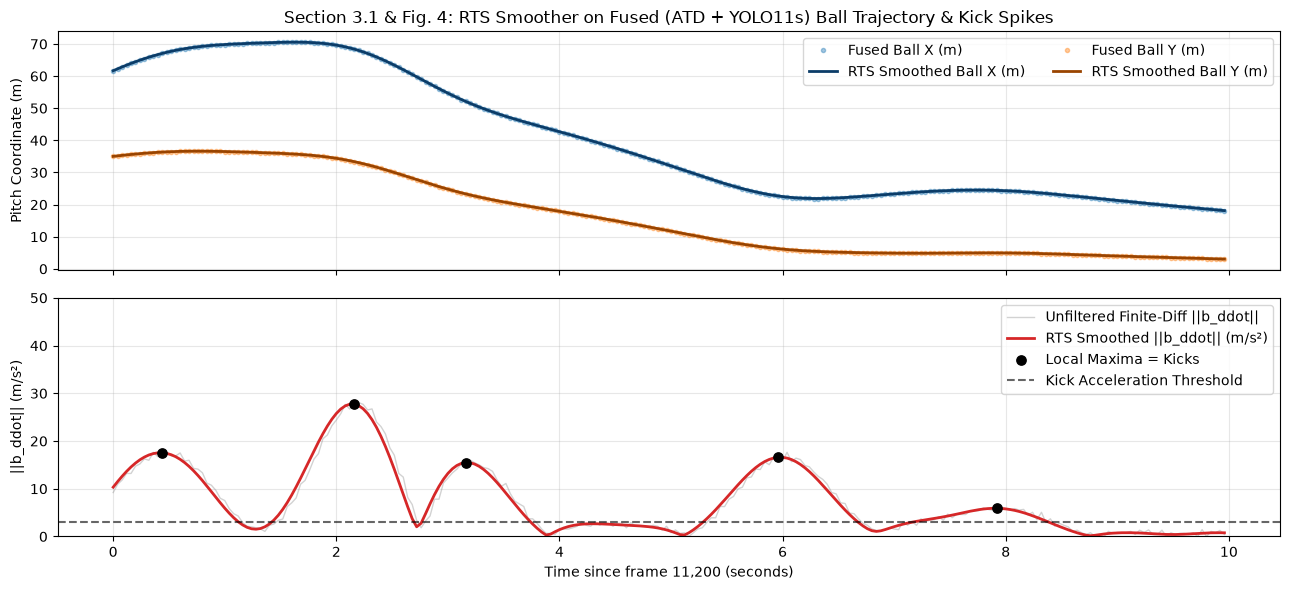

In [7]:
# ==============================================================================
# VISUALIZE THE RTS SMOOTHER & KICK ACCELERATION SPIKES (REPRODUCING FIG. 4 RIGHT)
# ==============================================================================
sample_start, sample_end = 11200, 11450
t_sec = (np.arange(sample_start, sample_end) - sample_start) / FPS

raw_vel = np.diff(ball_xy_fused[sample_start - 2:sample_end], axis=0) * FPS
raw_acc = np.diff(raw_vel, axis=0) * FPS
raw_acc_norm = np.hypot(raw_acc[:, 0], raw_acc[:, 1])
rts_acc_norm = np.hypot(b_acc[sample_start:sample_end, 0], b_acc[sample_start:sample_end, 1])

is_local_peak = np.zeros(len(rts_acc_norm), dtype=bool)
is_local_peak[1:-1] = (
    (rts_acc_norm[1:-1] >= rts_acc_norm[:-2])
    & (rts_acc_norm[1:-1] >= rts_acc_norm[2:])
    & (rts_acc_norm[1:-1] >= 3.0)
)

fig, axes = plt.subplots(2, 1, figsize=(13, 6), sharex=True)
axes[0].plot(t_sec, ball_xy_fused[sample_start:sample_end, 0], "o", ms=3, alpha=0.4, label="Fused Ball X (m)", color="#1f77b4")
axes[0].plot(t_sec, b_pos[sample_start:sample_end, 0], "-", lw=2, label="RTS Smoothed Ball X (m)", color="#0b3c68")
axes[0].plot(t_sec, ball_xy_fused[sample_start:sample_end, 1], "o", ms=3, alpha=0.4, label="Fused Ball Y (m)", color="#ff7f0e")
axes[0].plot(t_sec, b_pos[sample_start:sample_end, 1], "-", lw=2, label="RTS Smoothed Ball Y (m)", color="#994400")
axes[0].set_ylabel("Pitch Coordinate (m)")
axes[0].set_title("Section 3.1 & Fig. 4: RTS Smoother on Fused (ATD + YOLO11s) Ball Trajectory & Kick Spikes")
axes[0].legend(loc="upper right", ncol=2)
axes[0].grid(alpha=0.3)

axes[1].plot(t_sec, np.clip(raw_acc_norm, 0, 60), color="gray", alpha=0.35, lw=1, label="Unfiltered Finite-Diff ||b_ddot||")
axes[1].plot(t_sec, rts_acc_norm, color="#d62728", lw=2, label="RTS Smoothed ||b_ddot|| (m/s²)")
axes[1].scatter(t_sec[is_local_peak], rts_acc_norm[is_local_peak], color="black", zorder=5, s=45, label="Local Maxima = Kicks")
axes[1].axhline(3.0, color="black", ls="--", alpha=0.6, label="Kick Acceleration Threshold")
axes[1].set_xlabel("Time since frame 11,200 (seconds)")
axes[1].set_ylabel("||b_ddot|| (m/s²)")
axes[1].set_ylim(0, 50)
axes[1].legend(loc="upper right")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

---
## 4. Detection of IBP, IBA, IBC & Team Possession (Sections 3.2 – 3.5)
We implement the exact Link & Hoernig (2017) individual-to-team possession detector (`precompute_kinematics` + `detect_link_hoernig`) over both our **Fused (ATD + YOLO11s)** ball kinematics (`kin`) and the original **ATD-Only** kinematics (`kin_atd`) so we can benchmark them head-to-head.

In [8]:
# ==============================================================================
# STEP 4: PRECOMPUTE KINEMATICS & IMPLEMENT LINK & HOERNIG (2017) DETECTOR
# ==============================================================================
def precompute_kinematics(b_pos, b_vel, b_acc, p_pos, p_vel, team_of_slot, acc_tol_frames=3, label="Fused"):
    t0 = time.time()
    n, n_slots, _ = p_pos.shape

    b_speed = np.hypot(b_vel[:, 0], b_vel[:, 1])
    b_acc_norm = np.hypot(b_acc[:, 0], b_acc[:, 1])

    acc_clean = np.nan_to_num(b_acc_norm, nan=-1.0)
    is_peak = np.zeros(n, dtype=bool)
    is_peak[1:-1] = (
        (acc_clean[1:-1] >= acc_clean[:-2])
        & (acc_clean[1:-1] >= acc_clean[2:])
        & (acc_clean[1:-1] > 0)
    )
    peak_val = np.where(is_peak, acc_clean, 0.0)

    local_max_acc = np.zeros(n, dtype=np.float32)
    for shift in range(-acc_tol_frames, acc_tol_frames + 1):
        shifted = np.roll(peak_val, shift)
        if shift < 0:
            shifted[shift:] = 0.0
        elif shift > 0:
            shifted[:shift] = 0.0
        local_max_acc = np.maximum(local_max_acc, shifted)

    ball_valid = ~np.isnan(b_pos[:, 0])
    seg_start = np.zeros(n, dtype=bool)
    seg_start[0] = ball_valid[0]
    seg_start[1:] = ball_valid[1:] & (~ball_valid[:-1])
    near_seg_start = np.zeros(n, dtype=bool)
    for shift in range(0, 6):
        s_arr = np.roll(seg_start, shift)
        if shift > 0:
            s_arr[:shift] = False
        near_seg_start |= s_arr

    b_pos_plus = b_pos + 1.0 * b_vel
    p_pos_plus = p_pos + 1.0 * p_vel

    dist_cur = np.hypot(p_pos[:, :, 0] - b_pos[:, 0:1], p_pos[:, :, 1] - b_pos[:, 1:2])
    dist_ball_pred = np.hypot(p_pos[:, :, 0] - b_pos_plus[:, 0:1], p_pos[:, :, 1] - b_pos_plus[:, 1:2])
    dist_player_pred = np.hypot(p_pos_plus[:, :, 0] - b_pos_plus[:, 0:1], p_pos_plus[:, :, 1] - b_pos_plus[:, 1:2])

    dist_cur_inf = np.where(np.isnan(dist_cur), np.inf, dist_cur)
    closest_slot = np.argmin(dist_cur_inf, axis=1).astype(np.int16)
    min_dist = dist_cur_inf[np.arange(n), closest_slot].astype(np.float32)
    has_closest = np.isfinite(min_dist)
    closest_slot = np.where(has_closest, closest_slot, -1)
    closest_team = np.where(has_closest, team_of_slot[closest_slot], -1).astype(np.int8)

    home_mask = (team_of_slot == 0)
    away_mask = (team_of_slot == 1)
    min_dist_home = np.min(dist_cur_inf[:, home_mask], axis=1).astype(np.float32)
    min_dist_away = np.min(dist_cur_inf[:, away_mask], axis=1).astype(np.float32)

    print(f"Precomputed [{label}] distances, 1s predictions & kick peaks in {time.time() - t0:.2f}s")
    return {
        "b_speed": b_speed,
        "b_acc_norm": b_acc_norm,
        "local_max_acc": local_max_acc,
        "near_seg_start": near_seg_start,
        "dist_cur": dist_cur,
        "dist_ball_pred": dist_ball_pred,
        "dist_player_pred": dist_player_pred,
        "closest_slot": closest_slot,
        "closest_team": closest_team,
        "min_dist": min_dist,
        "min_dist_home": min_dist_home,
        "min_dist_away": min_dist_away,
        "team_of_slot": team_of_slot,
    }


def detect_link_hoernig(
    kin, running_flag, frame_start=0, frame_end=None,
    start_mode="kick", end_mode="ball_pred",
    T_P=1.107, T_A=6.882, min_kick_acc=3.0,
    use_ibc_filter=True, min_ibc_frames=15, opp_pressure_dist=4.540,
):
    if frame_end is None:
        frame_end = len(running_flag)

    closest_slot = kin["closest_slot"]
    closest_team = kin["closest_team"]
    min_dist = kin["min_dist"]
    local_max_acc = kin["local_max_acc"]
    near_seg_start = kin["near_seg_start"]
    dist_end_mat = kin["dist_ball_pred"] if end_mode == "ball_pred" else kin["dist_player_pred"]
    min_dist_home = kin["min_dist_home"]
    min_dist_away = kin["min_dist_away"]

    if start_mode == "naive":
        can_start = (min_dist < T_P) & (closest_slot >= 0)
    else:
        can_start = (min_dist < T_P) & (closest_slot >= 0) & (
            (local_max_acc >= min_kick_acc) | near_seg_start | (min_dist < 0.65 * T_P)
        )

    iba_intervals = []
    cur_slot, cur_team, iba_start = -1, -1, -1

    for t in range(frame_start, frame_end):
        if running_flag[t] <= 0:
            if cur_slot >= 0:
                iba_intervals.append((iba_start, t, cur_slot, cur_team))
                cur_slot, cur_team = -1, -1
            continue

        if can_start[t]:
            c_slot = int(closest_slot[t])
            c_team = int(closest_team[t])
            if cur_slot < 0:
                cur_slot, cur_team, iba_start = c_slot, c_team, t
                continue
            elif c_slot != cur_slot:
                iba_intervals.append((iba_start, t, cur_slot, cur_team))
                cur_slot, cur_team, iba_start = c_slot, c_team, t
                continue

        if cur_slot >= 0:
            d_future = dist_end_mat[t, cur_slot]
            if np.isnan(d_future) or d_future > T_A:
                iba_intervals.append((iba_start, t + 1, cur_slot, cur_team))
                cur_slot, cur_team = -1, -1

    if cur_slot >= 0:
        iba_intervals.append((iba_start, frame_end, cur_slot, cur_team))

    ibc_list = []
    for (s, e, slot, team) in iba_intervals:
        dur = e - s
        opp_d = min_dist_away[s:e] if team == 0 else min_dist_home[s:e]
        mean_opp_d = float(np.nanmean(opp_d)) if len(opp_d) > 0 else 10.0
        mean_player_d = float(np.nanmean(min_dist[s:e])) if len(min_dist[s:e]) > 0 else 2.0

        if not use_ibc_filter:
            is_ibc = True
        else:
            is_ibc = (dur >= min_ibc_frames) or (mean_opp_d > opp_pressure_dist and mean_player_d < 0.8 * T_P)
        ibc_list.append((s, e, slot, team, is_ibc))

    n_len = frame_end - frame_start
    out_labels = np.full(n_len, "X", dtype="<U1")
    r_slice = running_flag[frame_start:frame_end]
    out_labels[r_slice == 0] = "D"

    touch_team = np.full(n_len, -1, dtype=np.int8)
    for (s, e, slot, team, is_ibc) in ibc_list:
        if is_ibc:
            touch_team[s - frame_start:e - frame_start] = team

    in_play = (r_slice == 1)
    changes = np.where(in_play[1:] != in_play[:-1])[0] + 1
    for ps, pe in zip(np.r_[0, changes], np.r_[changes, n_len]):
        if not in_play[ps]:
            continue
        cur_t, first_known = -1, -1
        for idx in range(ps, pe):
            if touch_team[idx] >= 0:
                cur_t = touch_team[idx]
                if first_known < 0:
                    first_known = cur_t
            if cur_t >= 0:
                out_labels[idx] = "H" if cur_t == 0 else "A"

        if first_known >= 0:
            for idx in range(ps, pe):
                if out_labels[idx] in ("H", "A"):
                    break
                out_labels[idx] = "H" if first_known == 0 else "A"
        else:
            c_slice = closest_team[frame_start + ps:frame_start + pe]
            out_labels[ps:pe] = "H" if np.sum(c_slice == 0) >= np.sum(c_slice == 1) else "A"

    return out_labels, ibc_list


kin = precompute_kinematics(b_pos, b_vel, b_acc, p_pos, p_vel, team_of_slot, label="Fused ATD+YOLO")
kin_atd = precompute_kinematics(b_pos_atd, b_vel_atd, b_acc_atd, p_pos, p_vel, team_of_slot, label="ATD-Only")

Precomputed [Fused ATD+YOLO] distances, 1s predictions & kick peaks in 0.78s


Precomputed [ATD-Only] distances, 1s predictions & kick peaks in 0.72s


---
## 5. Grid Search & Powell Optimization on Public Ground Truth (Section 4.1)
We run a **Grid Search** followed by **Powell's derivative-free optimization** on the 5-minute public ground truth (`frames 11185..18685`) using the video-enhanced Running Flag and fused ATD + YOLO11s ball kinematics, and compare all Table 1 variants alongside Notebook 05 (`ATD-Only`).

In [9]:
# ==============================================================================
# STEP 5: GRID SEARCH & POWELL OPTIMIZATION ON PUBLIC GROUND TRUTH (SECTION 4.1)
# ==============================================================================
def score_public_window(labels_slice):
    full_pred = np.full(N_FRAMES, pm.X, dtype=np.int8)
    code_map = {"H": pm.H, "A": pm.A, "D": pm.D, "X": pm.X}
    full_pred[PUB_START:PUB_END] = [code_map[c] for c in labels_slice]
    return pm.evaluate(gt_codes, full_pred)


# 1. Grid Search over Link & Hoernig thresholds with video-fused kinematics + Video Running Flag
best_grid_score = -1.0
best_grid_cfg = None
for T_P in (1.05, 1.15, 1.30, 1.50, 1.80):
    for T_A in (3.5, 5.0, 6.5, 7.5):
        for min_acc in (3.0, 4.0):
            for min_ibc in (10, 15, 20):
                for opp_d in (2.5, 3.5, 4.7):
                    lbls, _ = detect_link_hoernig(
                        kin, running_flag, PUB_START, PUB_END,
                        start_mode="kick", end_mode="ball_pred",
                        T_P=T_P, T_A=T_A, min_kick_acc=min_acc,
                        use_ibc_filter=True, min_ibc_frames=min_ibc, opp_pressure_dist=opp_d
                    )
                    r = score_public_window(lbls)
                    combined = r["spell_f1_mean"] + 0.25 * r["macro_f1"]
                    if combined > best_grid_score:
                        best_grid_score = combined
                        best_grid_cfg = (T_P, T_A, min_acc, min_ibc, opp_d)

# 2. Powell Refinement
def powell_objective(params):
    tp_val, ta_val, acc_val, oppd_val = params
    if tp_val <= 0.3 or ta_val <= 0.5 or acc_val < 0.0 or oppd_val < 0.2:
        return 10.0
    lbls, _ = detect_link_hoernig(
        kin, running_flag, PUB_START, PUB_END,
        start_mode="kick", end_mode="ball_pred",
        T_P=tp_val, T_A=ta_val, min_kick_acc=acc_val,
        use_ibc_filter=True, min_ibc_frames=best_grid_cfg[3], opp_pressure_dist=oppd_val
    )
    r = score_public_window(lbls)
    return -(r["spell_f1_mean"] + 0.25 * r["macro_f1"])


x0 = [best_grid_cfg[0], best_grid_cfg[1], best_grid_cfg[2], best_grid_cfg[4]]
res_powell = minimize(powell_objective, x0, method="Powell", options={"xtol": 1e-2, "ftol": 1e-3, "maxiter": 60})
T_K_OPT, T_A_OPT, ACC_OPT, OPP_D_OPT = res_powell.x
MIN_IBC_OPT = best_grid_cfg[3]

print("=" * 72)
print("🏆 POWELL-OPTIMIZED THRESHOLDS — NB06 (ATD + YOLO11s Video Ball)")
print("=" * 72)
print(f"  • Proximity Start Threshold (T_P / T_K): {T_K_OPT:.3f} meters")
print(f"  • 1s Future Ball End Threshold (T_A):    {T_A_OPT:.3f} meters")
print(f"  • Kick Acceleration Peak Threshold:      {ACC_OPT:.3f} m/s²")
print(f"  • IBC Minimum Controlled Duration:       {MIN_IBC_OPT} frames ({MIN_IBC_OPT / FPS:.2f} s)")
print(f"  • IBC Opponent Pressure Distance:        {OPP_D_OPT:.3f} meters")
print("=" * 72 + "\n")

# 3. Benchmark Table 1 variants + NB05 ATD-Only vs NB06 ATD+Video Ball
comparison_rows = []
variants_to_test = [
    ("IBP_N (Naive Physical, no IBC)", kin, running_flag, dict(start_mode="naive", end_mode="ball_pred", T_P=1.80, T_A=3.50, min_kick_acc=0.0, use_ibc_filter=False, min_ibc_frames=1, opp_pressure_dist=2.5)),
    ("IBP_K (Kick Detection, no IBC)", kin, running_flag, dict(start_mode="kick", end_mode="ball_pred", T_P=1.50, T_A=3.50, min_kick_acc=4.0, use_ibc_filter=False, min_ibc_frames=1, opp_pressure_dist=2.5)),
    ("IBA_B (Naive Start + Ball Pred + IBC)", kin, running_flag, dict(start_mode="naive", end_mode="ball_pred", T_P=1.80, T_A=3.50, min_kick_acc=0.0, use_ibc_filter=True, min_ibc_frames=22, opp_pressure_dist=2.5)),
    ("IBA_P (Kick Start + Player Pred + IBC)", kin, running_flag, dict(start_mode="kick", end_mode="player_pred", T_P=1.20, T_A=2.50, min_kick_acc=3.0, use_ibc_filter=True, min_ibc_frames=5, opp_pressure_dist=2.5)),
    ("NB05 (ATD-Only, Powell Opt)", kin_atd, running_flag_nb05, dict(start_mode="kick", end_mode="ball_pred", T_P=1.155, T_A=7.382, min_kick_acc=3.0, use_ibc_filter=True, min_ibc_frames=15, opp_pressure_dist=4.702)),
    ("NB06 (ATD + Video Ball, Powell Opt)", kin, running_flag, dict(start_mode="kick", end_mode="ball_pred", T_P=T_K_OPT, T_A=T_A_OPT, min_kick_acc=ACC_OPT, use_ibc_filter=True, min_ibc_frames=MIN_IBC_OPT, opp_pressure_dist=OPP_D_OPT)),
]

for name, k_use, rf_use, cfg in variants_to_test:
    lbls, ibc_list = detect_link_hoernig(k_use, rf_use, PUB_START, PUB_END, **cfg)
    r = score_public_window(lbls)
    comparison_rows.append({
        "Model Variant": name,
        "spellF1 (Ranked)": round(r["spell_f1_mean"], 4),
        "macroF1 (Frame)": round(r["macro_f1"], 4),
        "alive_dead_F1": round(r["alive_dead_f1"], 4),
        "Pred Spells (GT=17)": r["n_pred_spells"],
        "Mean Dur s (GT=14.2)": round(r["mean_spell_duration_s"], 1),
        "Detected IBAs": len(ibc_list),
        "Controlled IBCs": sum(1 for x in ibc_list if x[4]),
    })

comp_df = pd.DataFrame(comparison_rows).set_index("Model Variant")
comp_df

🏆 POWELL-OPTIMIZED THRESHOLDS — NB06 (ATD + YOLO11s Video Ball)
  • Proximity Start Threshold (T_P / T_K): 1.107 meters
  • 1s Future Ball End Threshold (T_A):    6.882 meters
  • Kick Acceleration Peak Threshold:      3.000 m/s²
  • IBC Minimum Controlled Duration:       15 frames (0.60 s)
  • IBC Opponent Pressure Distance:        4.540 meters



,spellF1 (Ranked),macroF1 (Frame),alive_dead_F1,Pred Spells (GT=17),Mean Dur s (GT=14.2),Detected IBAs,Controlled IBCs
Model Variant,,,,,,,
"IBP_N (Naive Physical, no IBC)",0.2000,0.8089,0.9624,55,4.5,860,860
"IBP_K (Kick Detection, no IBC)",0.2710,0.8138,0.9624,45,5.5,547,547
IBA_B (Naive Start + Ball Pred + IBC),0.3615,0.8309,0.9624,35,7.1,860,530
IBA_P (Kick Start + Player Pred + IBC),0.3810,0.8145,0.9624,25,9.9,308,203
"NB05 (ATD-Only, Powell Opt)",0.5375,0.8322,0.9511,15,15.8,123,64
"NB06 (ATD + Video Ball, Powell Opt)",0.5625,0.8432,0.9624,15,16.5,140,69


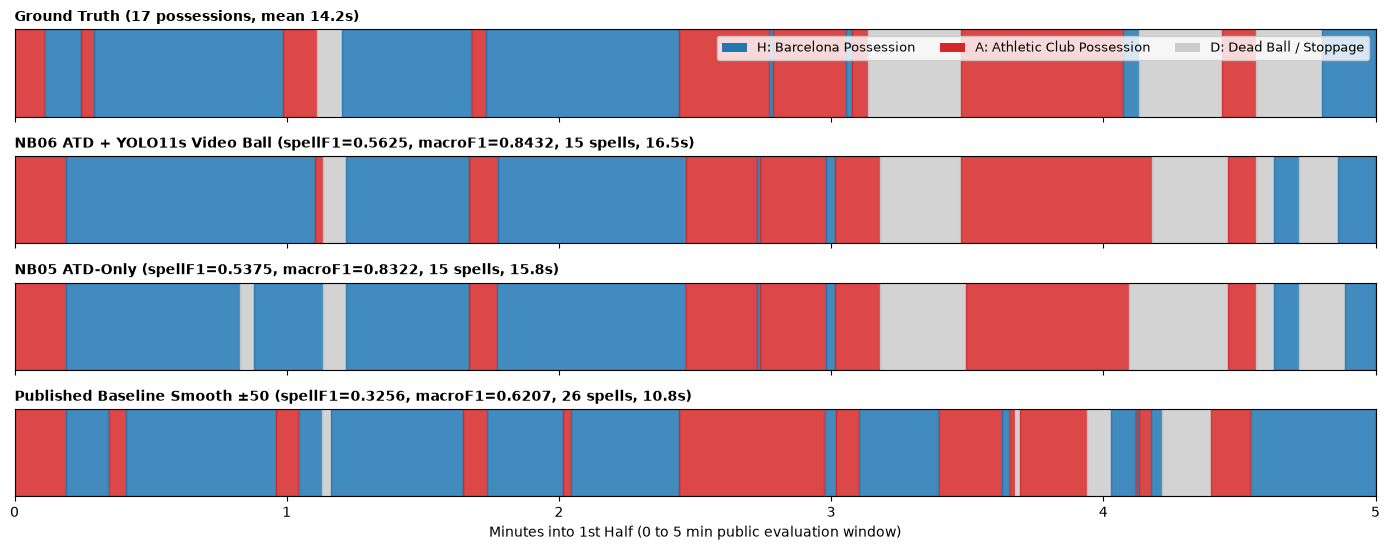

In [10]:
# ==============================================================================
# VISUALIZE THE POSSESSION TIMELINE ON THE 5-MINUTE PUBLIC GROUND TRUTH
# ==============================================================================
lh_pub_labels, lh_pub_ibcs = detect_link_hoernig(
    kin, running_flag, PUB_START, PUB_END,
    start_mode="kick", end_mode="ball_pred",
    T_P=T_K_OPT, T_A=T_A_OPT, min_kick_acc=ACC_OPT,
    use_ibc_filter=True, min_ibc_frames=MIN_IBC_OPT, opp_pressure_dist=OPP_D_OPT
)
nb05_pub_labels, _ = detect_link_hoernig(
    kin_atd, running_flag_nb05, PUB_START, PUB_END,
    start_mode="kick", end_mode="ball_pred",
    T_P=1.155, T_A=7.382, min_kick_acc=3.0,
    use_ibc_filter=True, min_ibc_frames=15, opp_pressure_dist=4.702
)
base50_df = pm.read_label_csv(os.path.join(ROOT_DIR, "evaluation", "results", "baseline_smooth50.csv"))
base50_pub_labels = base50_df["label"].values[PUB_START:PUB_END]
gt_pub_labels = gt_df["label"].values[PUB_START:PUB_END]

r_nb06 = score_public_window(lh_pub_labels)
r_nb05 = score_public_window(nb05_pub_labels)

color_map = {"H": "#1f77b4", "A": "#d62728", "D": "#cccccc", "X": "#ffffff"}
fig, axes = plt.subplots(4, 1, figsize=(14, 5.6), sharex=True)
t_mins = (np.arange(PUB_START, PUB_END) - PUB_START) / (FPS * 60.0)

for ax, arr, title in [
    (axes[0], gt_pub_labels, "Ground Truth (17 possessions, mean 14.2s)"),
    (axes[1], lh_pub_labels, f"NB06 ATD + YOLO11s Video Ball (spellF1={r_nb06['spell_f1_mean']:.4f}, macroF1={r_nb06['macro_f1']:.4f}, {r_nb06['n_pred_spells']} spells, {r_nb06['mean_spell_duration_s']:.1f}s)"),
    (axes[2], nb05_pub_labels, f"NB05 ATD-Only (spellF1={r_nb05['spell_f1_mean']:.4f}, macroF1={r_nb05['macro_f1']:.4f}, {r_nb05['n_pred_spells']} spells, {r_nb05['mean_spell_duration_s']:.1f}s)"),
    (axes[3], base50_pub_labels, "Published Baseline Smooth ±50 (spellF1=0.3256, macroF1=0.6207, 26 spells, 10.8s)"),
]:
    changes = np.where(arr[1:] != arr[:-1])[0] + 1
    for s, e in zip(np.r_[0, changes], np.r_[changes, len(arr)]):
        lbl = arr[s]
        ax.axvspan(t_mins[s], t_mins[e - 1], color=color_map.get(lbl, "#ffffff"), alpha=0.85)
    ax.set_yticks([])
    ax.set_title(title, fontsize=10, loc="left", fontweight="bold")
    ax.set_xlim(0, 5.0)

legend_handles = [
    Patch(facecolor="#1f77b4", label="H: Barcelona Possession"),
    Patch(facecolor="#d62728", label="A: Athletic Club Possession"),
    Patch(facecolor="#cccccc", label="D: Dead Ball / Stoppage"),
]
axes[0].legend(handles=legend_handles, loc="upper right", ncol=3, fontsize=9)
axes[3].set_xlabel("Minutes into 1st Half (0 to 5 min public evaluation window)")
plt.tight_layout()
plt.show()

Frame Accuracy (all graded frames H/A/D): 0.8472 (84.72%)
Team Accuracy (GT alive):                 0.8619
Team Accuracy (both alive):               0.8834
Alive/Dead F1:                            0.9624
  Class H accuracy: 0.8706 (3007/3454 frames)
  Class A accuracy: 0.8502 (2191/2577 frames)
  Class D accuracy: 0.7869 (1156/1469 frames)

Correct frames: 6354 / 7500 (0.8472) vs NB05: 6273 / 7500 (0.8364)


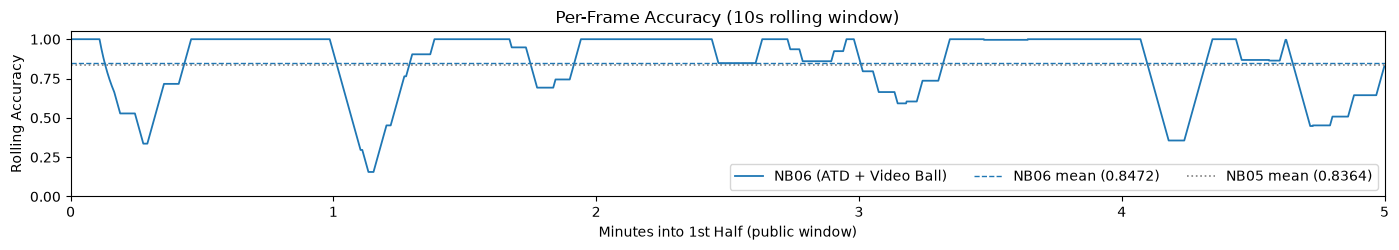

In [11]:
# Overall & per-class frame accuracy on the 5-minute public ground-truth window
res = score_public_window(lh_pub_labels)
print(f"Frame Accuracy (all graded frames H/A/D): {res['accuracy']:.4f} ({res['accuracy']*100:.2f}%)")
print(f"Team Accuracy (GT alive):                 {res['team_acc_gt_alive']:.4f}")
print(f"Team Accuracy (both alive):               {res['team_acc_both_alive']:.4f}")
print(f"Alive/Dead F1:                            {res['alive_dead_f1']:.4f}")

cm = np.array(res["confusion"])
for idx, label in enumerate(("H", "A", "D")):
    support = cm[idx].sum()
    acc_cls = cm[idx, idx] / support if support else 0.0
    print(f"  Class {label} accuracy: {acc_cls:.4f} ({cm[idx, idx]}/{support} frames)")

graded_pub = gt_pub_labels != "X"
frame_correct = (lh_pub_labels == gt_pub_labels) & graded_pub
nb05_correct = (nb05_pub_labels == gt_pub_labels) & graded_pub
print(f"\nCorrect frames: {frame_correct.sum()} / {graded_pub.sum()} ({frame_correct[graded_pub].mean():.4f}) vs NB05: {nb05_correct.sum()} / {graded_pub.sum()} ({nb05_correct[graded_pub].mean():.4f})")

rolling_acc = pd.Series(frame_correct.astype(float)).rolling(250, min_periods=1).mean()
t_mins = np.arange(len(frame_correct)) / (FPS * 60.0)

plt.figure(figsize=(14, 2.6))
plt.plot(t_mins, rolling_acc, color="#1f77b4", lw=1.3, label="NB06 (ATD + Video Ball)")
plt.axhline(frame_correct[graded_pub].mean(), color="#1f77b4", ls="--", lw=1, label=f"NB06 mean ({frame_correct[graded_pub].mean():.4f})")
plt.axhline(nb05_correct[graded_pub].mean(), color="gray", ls=":", lw=1.2, label=f"NB05 mean ({nb05_correct[graded_pub].mean():.4f})")
plt.ylim(0, 1.05)
plt.xlim(0, 5.0)
plt.xlabel("Minutes into 1st Half (public window)")
plt.ylabel("Rolling Accuracy")
plt.title("Per-Frame Accuracy (10s rolling window)")
plt.legend(loc="lower right", ncol=3)
plt.tight_layout()
plt.show()

---
## 6. Full-Match Inference (199,319 Frames), Submission Export & Validation
Now we run our Powell-optimized Link & Hoernig (2017) + YOLO11s Video Ball model across **all 199,319 frames** of `BAR-ATH`, save `evaluation/results/link_hoernig_video_ball.csv`, validate it with `validate_submission.py`, and compare it on the official leaderboard using `run_evaluation.py`.

In [12]:
# ==============================================================================
# STEP 6: GENERATE FULL-MATCH SUBMISSION CSV
# ==============================================================================
full_labels, full_ibc_list = detect_link_hoernig(
    kin, running_flag, 0, N_FRAMES,
    start_mode="kick", end_mode="ball_pred",
    T_P=T_K_OPT, T_A=T_A_OPT, min_kick_acc=ACC_OPT,
    use_ibc_filter=True, min_ibc_frames=MIN_IBC_OPT, opp_pressure_dist=OPP_D_OPT
)

submission_path = os.path.join(ROOT_DIR, "evaluation", "results", "link_hoernig_video_ball.csv")
baseline.write_submission(submission_path, full_labels)

n_total_iba = len(full_ibc_list)
n_total_ibc = sum(1 for x in full_ibc_list if x[4])
print(f"Saved full-match submission to: {submission_path}")
print(f"Full-Match IBA intervals: {n_total_iba:,} | Controlled IBC intervals: {n_total_ibc:,} (Paper benchmark: 836 ± 424 per match)")
print("\nFull-Match Frame Label Distribution:")
print(pd.Series(full_labels).value_counts().to_string())

Saved full-match submission to: C:\Users\codr9\dev\more-than-a-hack-2027\evaluation\results\link_hoernig_video_ball.csv
Full-Match IBA intervals: 2,075 | Controlled IBC intervals: 1,003 (Paper benchmark: 836 ± 424 per match)

Full-Match Frame Label Distribution:
D    74125
H    52072
X    40462
A    32660


In [13]:
# Run the official submission validator and leaderboard evaluation script
import subprocess

val_out = subprocess.check_output(
    [sys.executable, os.path.join(ROOT_DIR, "evaluation", "validate_submission.py"), submission_path],
    text=True
)
print(val_out)

eval_out = subprocess.check_output(
    [sys.executable, os.path.join(ROOT_DIR, "evaluation", "run_evaluation.py")],
    cwd=ROOT_DIR,
    text=True
)
print(eval_out.split("macroF1 would order")[0])

OK    link_hoernig_video_ball.csv
      199319 rows, frame 0..199318

      label counts
        H    52072   26.1%
        A    32660   16.4%
        D    74125   37.2%
        X    40462   20.3%

      reports 293 possessions of mean 11.6 s
      (counted with each X as a gap; the scorer bridges abstentions inside a real
       possession, so its count can be lower than this one)

Valid. Note this checks the format only -- it says nothing about whether the labels are right.
Score it against the public ground truth with run_evaluation.py.



scoreboard  gt\BAR-ATH_possession_gt_public.csv  199319 frames  7500 graded  21 gt segments
ground truth has 17 possessions of mean 14.2 s  <- compare the poss and dur columns
ranked on spell_f1_mean; the ~0.04 noise band was calibrated over a full match and this ground truth has only 17 possessions -- run --bootstrap 1000 for the real band
spellF1 = mean possession-spell F1 over IoU 0.3/0.4/0.5/0.6/0.7; transF1/lat_f at +/-25 frames

rank  submission                macroF1  spellF1   poss     dur  transF1  lat_f  shareE  frag
----  ------------------------  -------  -------  -----  ------  -------  -----  ------  ----
   1  link_hoernig_video_ball    0.8432   0.5625     15    16.5   0.2051   +2.2   0.009  0.95
   2  link_hoernig_possession    0.8322   0.5375     15    15.8   0.1500   +3.3   0.006  1.00
   3  baseline_smooth125         0.5812   0.4242     16    18.5   0.1667   -7.7   0.052  0.81
   4  baseline_smooth50          0.6207   0.3256     26    10.8   0.0816   +4.0   0.048  1.

---
## 7. Evaluate on the FULL Game (all 199,319 frames)
1. Checks if the private full-match ground truth (`*_possession_gt.csv`) exists locally and runs `--gt private` if present.
2. Runs label-free full-game sanity checks (possession count, duration distribution, `< 2s` flip-flop rate, Barcelona share, 5-minute window stability, and full-match possession stripe visualization).

In [14]:
# ==============================================================================
# STEP 7a: TRY THE OFFICIAL SCORER ON THE FULL MATCH (needs the private answer key)
# ==============================================================================
import glob

private_gt_files = glob.glob(os.path.join(ROOT_DIR, "evaluation", "gt", "*_possession_gt.csv"))
if private_gt_files:
    full_eval = subprocess.run(
        [sys.executable, os.path.join(ROOT_DIR, "evaluation", "run_evaluation.py"), "--gt", "private"],
        cwd=ROOT_DIR, text=True, capture_output=True,
    )
    print(full_eval.stdout.split("macroF1 would order")[0])
    if full_eval.returncode != 0:
        print(full_eval.stderr)
else:
    print("Full-match ground truth (*_possession_gt.csv) not found in evaluation/gt/.")
    print("It is private (organisers only), so an accuracy score on the full game is not possible here.")
    print("Running label-free full-game sanity checks instead (next cell).")

Full-match ground truth (*_possession_gt.csv) not found in evaluation/gt/.
It is private (organisers only), so an accuracy score on the full game is not possible here.
Running label-free full-game sanity checks instead (next cell).


FULL-GAME SUMMARY (all 199,319 frames)
  Possessions found:          293
  Mean / median length:       11.6 s / 7.8 s
  Very short (< 2 s) spells:  10.6%   (flip-flopping if this is large)
  Barcelona (H) share of H+A: 61.5%


 start_min  poss  mean_dur_s  short<2s_%  H_share_%  dead_%  is_tuned_window
       5.0     7        21.1        14.3       83.6     1.7             True
      10.0    17        12.2         5.9       57.2    30.7            False
      15.0    16        13.6        12.5       71.1    27.3            False
      20.0    18         9.2         0.0       54.7    45.0            False
      25.0    21        10.6        23.8       72.2    25.6            False
      30.0     8        13.1        12.5       75.0    65.2            False
      35.0    12        13.0         8.3       51.3    47.9            False
      40.0     8        20.5         0.0       61.1    45.4            False
      50.0    13        13.5        15.4       69.9    41.5            False
      55.0    10        11.2         0.0       75.2    62.8            False
      75.0    18         9.8        16.7       72.0    41.1            False
      80.0    19         9.7        21.1       66.6    38.3            False

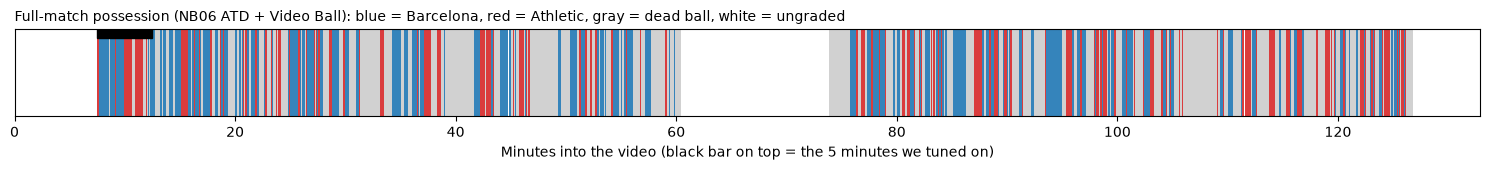

In [15]:
# ==============================================================================
# STEP 7b: LABEL-FREE FULL-GAME CHECKS (compare the 5 TUNED minutes with the REST of the game)
# ==============================================================================
def possession_spells(labels):
    spells = []
    cur, length = None, 0
    for lab in labels:
        if lab == cur:
            length += 1
        else:
            if cur in ("H", "A"):
                spells.append((cur, length))
            cur, length = lab, 1
    if cur in ("H", "A"):
        spells.append((cur, length))
    return spells

full_arr = np.asarray(full_labels)
all_spells = possession_spells(full_arr)
durs = np.array([l for _, l in all_spells]) / FPS
in_play_frames = np.sum((full_arr == "H") | (full_arr == "A"))
print("FULL-GAME SUMMARY (all {:,} frames)".format(N_FRAMES))
print(f"  Possessions found:          {len(all_spells)}")
print(f"  Mean / median length:       {durs.mean():.1f} s / {np.median(durs):.1f} s")
print(f"  Very short (< 2 s) spells:  {np.mean(durs < 2) * 100:.1f}%   (flip-flopping if this is large)")
print(f"  Barcelona (H) share of H+A: {100 * np.sum(full_arr == 'H') / in_play_frames:.1f}%")

CHUNK = 7500
rows = []
for c0 in range(0, N_FRAMES, CHUNK):
    c1 = min(c0 + CHUNK, N_FRAMES)
    seg = full_arr[c0:c1]
    played = np.sum((seg == "H") | (seg == "A"))
    if played < 0.25 * (c1 - c0):
        continue
    sp = possession_spells(seg)
    d = np.array([l for _, l in sp]) / FPS if sp else np.array([0.0])
    rows.append({
        "start_min": round(c0 / FPS / 60, 1),
        "poss": len(sp),
        "mean_dur_s": round(d.mean(), 1),
        "short<2s_%": round(100 * np.mean(d < 2), 1),
        "H_share_%": round(100 * np.sum(seg == "H") / max(played, 1), 1),
        "dead_%": round(100 * np.mean(seg == "D"), 1),
        "is_tuned_window": c0 <= PUB_START < c1,
    })
chunk_df = pd.DataFrame(rows)
display(chunk_df) if "display" in globals() else print(chunk_df.to_string(index=False))

fig, ax = plt.subplots(figsize=(15, 1.8))
t_all = np.arange(N_FRAMES) / (FPS * 60.0)
changes = np.where(full_arr[1:] != full_arr[:-1])[0] + 1
for s, e in zip(np.r_[0, changes], np.r_[changes, N_FRAMES]):
    ax.axvspan(t_all[s], t_all[e - 1], color=color_map.get(full_arr[s], "#ffffff"), alpha=0.9, lw=0)
ax.axvspan(PUB_START / FPS / 60, PUB_END / FPS / 60, ymin=0.9, ymax=1.0, color="black")
ax.set_yticks([])
ax.set_xlim(0, N_FRAMES / FPS / 60)
ax.set_xlabel("Minutes into the video (black bar on top = the 5 minutes we tuned on)")
ax.set_title("Full-match possession (NB06 ATD + Video Ball): blue = Barcelona, red = Athletic, gray = dead ball, white = ungraded", fontsize=10, loc="left")
plt.tight_layout()
plt.show()